In [101]:
import torch, torchvision, numpy as np, matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split, Subset
import torch.nn as nn, torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import datasets, transforms
import seaborn as sns
from collections import Counter
from PIL import Image
from sklearn.model_selection import train_test_split
import torchvision.transforms as T
import sys
import subprocess
import time
from tqdm import tqdm
import copy

In [102]:
print("Загрузка данных...")
train_full = datasets.CIFAR10(root="data", train=True,  download=True, transform=None)
test_full  = datasets.CIFAR10(root="data", train=False, download=True, transform=None)

Загрузка данных...


In [103]:
print("=== train_full ===")
print(f"Количество изображений: {len(train_full)}")

print("\n=== test_full ===")
print(f"Количество изображений: {len(test_full)}")

=== train_full ===
Количество изображений: 50000

=== test_full ===
Количество изображений: 10000


In [104]:
def show_im(CLASSES, labels, images):
    # По 5 примеров на каждый класс
    samples_per_class = 8
    cell = 0.9

    fig, axes = plt.subplots(
        nrows=len(CLASSES),
        ncols=samples_per_class,
        figsize=(samples_per_class * cell, len(CLASSES) * cell)
    )

    for class_idx, class_name in enumerate(CLASSES):
        # индексы всех картинок этого класса
        idxs = (labels == class_idx).nonzero(as_tuple=True)[0]
        # первые 5
        chosen = idxs[:samples_per_class]

        for j, idx in enumerate(chosen):
            ax = axes[class_idx, j]
            img = images[idx]
            ax.imshow(img.permute(1, 2, 0).numpy(), interpolation='nearest')
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(class_name, fontsize=11, rotation=0,
                              labelpad=40, va='center')

    plt.suptitle("CIFAR-10: 5 примеров на класс", fontsize=14)
    plt.tight_layout()
    plt.show()

In [105]:
print("Разделяем данные")

# Правильное разделение train на train + val (45 000 / 5 000)
# Используем стратификацию, чтобы классы были равномерны
idx_train, idx_val = train_test_split(
    np.arange(len(train_full)),
    test_size=5000,
    stratify=train_full.targets,
    random_state=42
)

train_data = Subset(train_full, idx_train) # 45 000
val_data   = Subset(train_full, idx_val)   # 5 000
test_data  = test_full                     # 10 000

print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")

Разделяем данные
Train: 45000, Val: 5000, Test: 10000


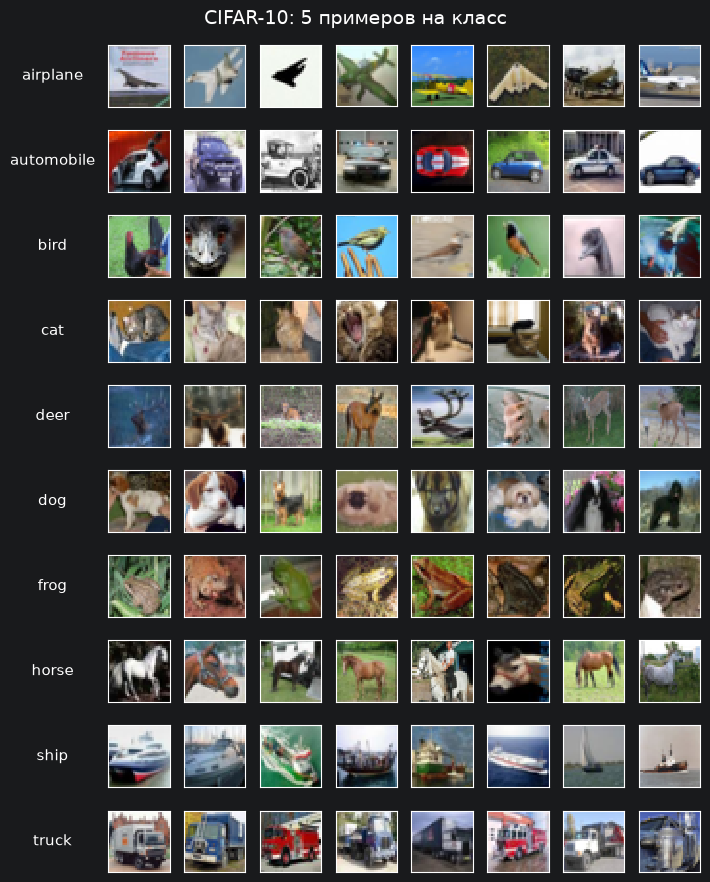

In [106]:
to_tensor = T.ToTensor()

images = torch.stack([to_tensor(img) for img, _ in test_full])
labels = torch.tensor([label for _, label in test_full])

# Классы CIFAR-10
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

show_im(CLASSES, labels, images)

In [107]:
def balans(data):
    print("Проводим анализ датасета")

    # Достаём список меток и список имён классов ---
    if hasattr(data, "indices") and hasattr(data, "dataset"):
        # Subset из random_split
        base = data.dataset
        if hasattr(base, "targets"):
            all_lb = base.targets
        else:
            all_lb = [y for _, y in base.samples]
        lb = [all_lb[i] for i in data.indices]
        class_names = base.classes

    elif hasattr(data, "targets"):
        # CIFAR10 / MNIST напрямую
        lb = list(data.targets)
        class_names = data.classes

    elif hasattr(data, "samples"):
        # ImageFolder напрямую
        lb = [y for _, y in data.samples]
        class_names = data.classes

    else:
        lb = [int(y) for _, y in data]
        class_names = getattr(data, "classes", [str(i) for i in range(max(lb)+1)])

    cn = Counter(lb)

    s = sum(cn.values())

    print(f"Число изображений: {s}")

    # красивый вывод с именами классов
    for idx, name in enumerate(class_names):
        print(f"{name:>10}: {cn[idx]:>6}  ({cn[idx]/len(lb):.1%})")

In [108]:
def size_im(data, max_n=None):
    # Возвращает список (height, width, channels) для изображений датасета

    if hasattr(data, "indices") and hasattr(data, "dataset"):
        base = data.dataset
        if hasattr(base, "data") and getattr(base.data, "ndim", 0) == 4:
            _, H, W, C = base.data.shape
            return [(H, W, C)] * len(data.indices)     # все одинаковые
        paths = [base.samples[i][0] for i in data.indices]
        return [Image.open(p).size[::-1] + (len(Image.open(p).getbands()),)
                for p in paths]

    if hasattr(data, "data") and getattr(data.data, "ndim", 0) == 4:
        _, H, W, C = data.data.shape
        return [(H, W, C)] * len(data)

    if hasattr(data, "samples"):
        sizes = []
        for p, _ in data.samples:
            with Image.open(p) as im:
                sizes.append((im.height, im.width, len(im.getbands())))
        return sizes

    if max_n is None:
        max_n = len(data)
    sizes = []
    for i in range(min(max_n, len(data))):
        x, _ = data[i]
        sizes.append((x.shape[-2], x.shape[-1], x.shape[-3]))
    return sizes

In [109]:
balans(train_full)

Проводим анализ датасета
Число изображений: 50000
  airplane:   5000  (10.0%)
automobile:   5000  (10.0%)
      bird:   5000  (10.0%)
       cat:   5000  (10.0%)
      deer:   5000  (10.0%)
       dog:   5000  (10.0%)
      frog:   5000  (10.0%)
     horse:   5000  (10.0%)
      ship:   5000  (10.0%)
     truck:   5000  (10.0%)


In [110]:
balans(test_full)

Проводим анализ датасета
Число изображений: 10000
  airplane:   1000  (10.0%)
automobile:   1000  (10.0%)
      bird:   1000  (10.0%)
       cat:   1000  (10.0%)
      deer:   1000  (10.0%)
       dog:   1000  (10.0%)
      frog:   1000  (10.0%)
     horse:   1000  (10.0%)
      ship:   1000  (10.0%)
     truck:   1000  (10.0%)


In [111]:
sizes = size_im(train_data)
print("Уникальные размеры:", set(sizes))

Уникальные размеры: {(32, 32, 3)}


In [112]:
balans(train_data)

Проводим анализ датасета
Число изображений: 45000
  airplane:   4500  (10.0%)
automobile:   4500  (10.0%)
      bird:   4500  (10.0%)
       cat:   4500  (10.0%)
      deer:   4500  (10.0%)
       dog:   4500  (10.0%)
      frog:   4500  (10.0%)
     horse:   4500  (10.0%)
      ship:   4500  (10.0%)
     truck:   4500  (10.0%)


In [113]:
balans(val_data)

Проводим анализ датасета
Число изображений: 5000
  airplane:    500  (10.0%)
automobile:    500  (10.0%)
      bird:    500  (10.0%)
       cat:    500  (10.0%)
      deer:    500  (10.0%)
       dog:    500  (10.0%)
      frog:    500  (10.0%)
     horse:    500  (10.0%)
      ship:    500  (10.0%)
     truck:    500  (10.0%)


In [114]:
balans(test_data)

Проводим анализ датасета
Число изображений: 10000
  airplane:   1000  (10.0%)
automobile:   1000  (10.0%)
      bird:   1000  (10.0%)
       cat:   1000  (10.0%)
      deer:   1000  (10.0%)
       dog:   1000  (10.0%)
      frog:   1000  (10.0%)
     horse:   1000  (10.0%)
      ship:   1000  (10.0%)
     truck:   1000  (10.0%)


In [115]:
# Считает среднее и стандартное отклонение для каждого канала датасета
# Возвращает значения в диапазоне [0, 1]

def compute_mean_std(dataset, num_workers=0):

    loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=num_workers)

    # Суммы для каждого канала
    channels_sum = torch.zeros(3)
    channels_sq_sum = torch.zeros(3)
    num_samples = 0

    print("Подсчет mean и std...")
    for images, _ in loader:

        batch_size = images.size(0)
        images = images.view(batch_size, images.size(1), -1)

        # Суммируем по всем пикселям и батчам
        channels_sum += images.sum(dim=[0, 2])
        channels_sq_sum += (images ** 2).sum(dim=[0, 2])
        num_samples += images.size(2) * batch_size

    # Среднее
    mean = channels_sum / num_samples

    # Стандартное отклонение: sqrt(E[X²] - E[X]²)
    std = torch.sqrt(channels_sq_sum / num_samples - mean ** 2)

    return mean.tolist(), std.tolist()

# Создаем временную обертку, которая применяет ToTensor к "сырым" PIL-картинкам
class DatasetWithToTensor:
    def __init__(self, raw_dataset):
        self.raw_dataset = raw_dataset
        self.transform = T.ToTensor()

    def __len__(self):
        return len(self.raw_dataset)

    def __getitem__(self, idx):
        img, target = self.raw_dataset[idx]
        # Превращаем PIL в тензор прямо здесь
        return self.transform(img), target

# Оборачиваем наш "сырой" train_full
train_for_stats = DatasetWithToTensor(train_full)

# Считаем mean и std (используем num_workers=0 для стабильности в Jupyter/Windows)
mean, std = compute_mean_std(train_for_stats, num_workers=0)

Подсчет mean и std...


In [116]:
# Визуализирует оригинальное изображение и его аугментированные версии в сетке

# Показывает примеры из датасета с аугментациями для каждого класса

def show_augmented_samples(dataset, classes, samples_per_class=3, num_augs=4):

    # Трансформ для визуализации (без RandomErasing)
    vis_tf = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    # Трансформ для денормализации
    inv_normalize = transforms.Normalize(
        mean=[-m/s for m, s in zip(mean, std)],
        std=[1/s for s in std]
    )

    # Для каждого класса
    for class_idx, class_name in enumerate(classes):
        # Находим индексы всех изображений этого класса
        indices = [i for i, (_, label) in enumerate(dataset) if label == class_idx]
        chosen_indices = indices[:samples_per_class]

        # Уменьшаем figsize: было (num_augs + 1) * 1.5, стало * 0.8
        fig, axes = plt.subplots(
            samples_per_class,
            num_augs + 1,
            figsize=((num_augs + 1) * 0.8, samples_per_class * 0.8)  # ← УМЕНЬШЕНО
        )

        # Если только один пример, axes не будет массивом
        if samples_per_class == 1:
            axes = axes.reshape(1, -1)

        for row, idx in enumerate(chosen_indices):
            img_pil, label = dataset[idx]

            # Оригинальное изображение
            axes[row, 0].imshow(img_pil)
            axes[row, 0].set_title("Orig", fontsize=6)
            axes[row, 0].axis("off")

            # Аугментированные версии
            for col in range(1, num_augs + 1):
                aug_tensor = vis_tf(img_pil)
                aug_img = inv_normalize(aug_tensor).permute(1, 2, 0).numpy()
                aug_img = np.clip(aug_img, 0, 1)

                axes[row, col].imshow(aug_img)
                axes[row, col].set_title(f"Aug{col}", fontsize=6)
                axes[row, col].axis("off")

        # Уменьшаем отступы между изображениями
        plt.subplots_adjust(
            wspace=0.05,  # горизонтальный отступ
            hspace=0.05,  # вертикальный отступ
            top=0.9,      # отступ сверху для заголовка
            bottom=0.1    # отступ снизу
        )

        plt.suptitle(f"Class: {class_name}", fontsize=9, fontweight='bold', y=0.98)
        plt.show()

In [117]:
# Вычисляем среднее и стандартное отклонение по RGB, так как нужно превести изображеняи к числам, чтобы модель плавнее обучала необходимо произвести нормализацию, чтобы превести к числам близкие к 0
print(f"Mean: {[round(m, 4) for m in mean]}")
print(f"Std:  {[round(s, 4) for s in std]}")

Mean: [0.4914, 0.4822, 0.4465]
Std:  [0.247, 0.2435, 0.2616]


In [118]:
# print(" Jupyter использует этот Python:")
# print(sys.executable)
# print("-" * 60)
#
# print(" Удаляем всё лишнее из этого окружения...")
# subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "torch", "torchvision", "torchaudio", "-y"])
#
# print("\n Устанавливаем GPU-версию (CUDA 12.4) ИМЕННО в это окружение...")
# print(" Это займет 2-4 минуты (скачивается ~2.5 ГБ). Ждите завершения...")
# subprocess.check_call([
#     sys.executable, "-m", "pip", "install",
#     "torch", "torchvision", "torchaudio",
#     "--index-url", "https://download.pytorch.org/whl/cu124"
# ])
#
# print("\n УСТАНОВКА ЗАВЕРШЕНА!")
# print(" КРИТИЧЕСКИ ВАЖНО: Теперь нажмите в верхнем меню: Kernel -> Restart (или Restart & Clear Output)")

In [119]:
class DatasetWithTransform:
    def __init__(self, raw_dataset, indices, transform):
        self.raw_dataset = raw_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, target = self.raw_dataset[self.indices[idx]]
        if self.transform:
            img = self.transform(img)
        return img, target

In [120]:
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA compiled:   {torch.version.cuda}")
print(f"CUDA available:  {torch.cuda.is_available()}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"  Используемое устройство: {str(device).upper()}")

PyTorch version: 2.6.0+cu124
CUDA compiled:   12.4
CUDA available:  True
  Используемое устройство: CUDA


In [121]:
# Возвращает (всего параметров, обучаемых параметров)
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

In [122]:
print("Модель на основе VGG-стиля")

Модель на основе VGG-стиля


In [123]:
# Проводим нормализацию и аугментпацию для тренировочной выборки
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(), # Отражает по горизонтали изображение с вероятностью в 50%
    transforms.RandomRotation(10), # Поворот
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05), # Яркость, контраст, насыщенность, цветовой тон
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15))
    # закрашивает произвольный участок изображения с вероятностью 25 процентов, от 2 до 15 процентов
])

# Лучше RandomResizedCrop не использовать оно расширяет изображение. изображение и так низкого качества это просто ухудшид качество картрпнки, поэтому тут этот способ не подходит будем использовать способ который увеличвает на 4 пикселя с каждой строны и произвольно обрезает изображение до 32.

In [124]:
# Проводим нормализацию для тестовой и валидационной выборки
val_test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

print("Train transform: аугментации + нормализация")
print("Val/Test transform: только нормализация")

Train transform: аугментации + нормализация
Val/Test transform: только нормализация


In [125]:
print("СОЗДАНИЕ ФИНАЛЬНЫХ ДАТАСЕТОВ")

СОЗДАНИЕ ФИНАЛЬНЫХ ДАТАСЕТОВ


In [126]:
train_data = DatasetWithTransform(train_full, idx_train, train_tf)
val_data = DatasetWithTransform(train_full, idx_val, val_test_tf)
test_data = DatasetWithTransform(test_full, list(range(len(test_full))), val_test_tf)

print(f"Train: {len(train_data)} изображений")
print(f"Val:   {len(val_data)} изображений")
print(f"Test:  {len(test_data)} изображений")

Train: 45000 изображений
Val:   5000 изображений
Test:  10000 изображений


In [127]:
print("ВИЗУАЛИЗАЦИЯ АУГМЕНТАЦИЙ (8 примеров)")

ВИЗУАЛИЗАЦИЯ АУГМЕНТАЦИЙ (8 примеров)


ПОКАЗ АУГМЕНТАЦИЙ НА ТЕСТОВЫХ ИЗОБРАЖЕНИЯХ
Для каждого класса: 3 примера × (1 оригинал + 4 аугментации)


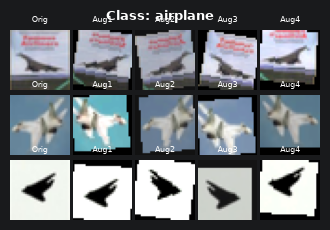

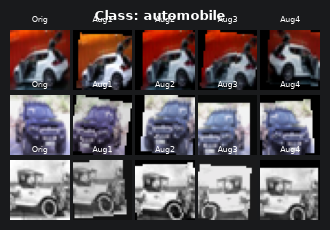

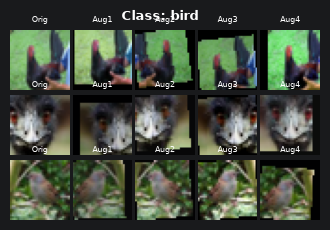

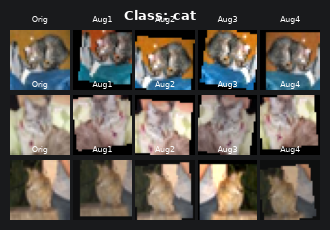

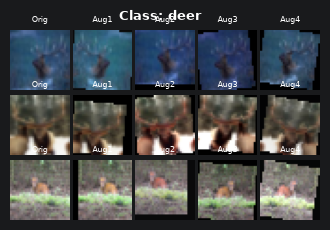

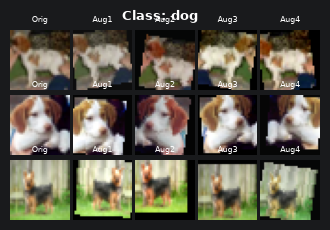

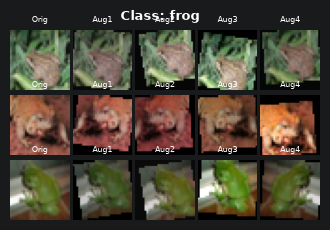

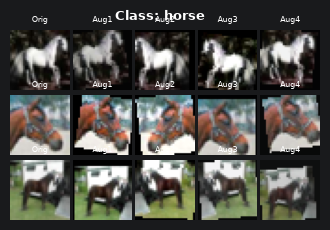

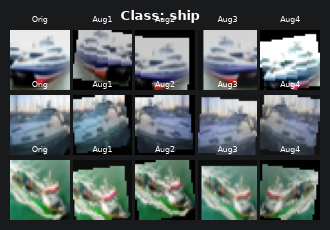

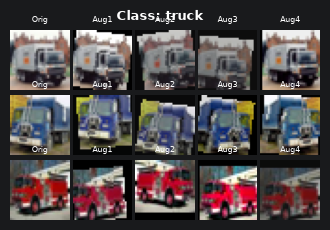

In [128]:
# ВЫЗОВ ФУНКЦИИ
print("ПОКАЗ АУГМЕНТАЦИЙ НА ТЕСТОВЫХ ИЗОБРАЖЕНИЯХ")
print("Для каждого класса: 3 примера × (1 оригинал + 4 аугментации)")

# Классы CIFAR-10
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

# Вызываем нашу новую функцию
show_augmented_samples(
    dataset=test_full,
    classes=CLASSES,
    samples_per_class=3,  # 3 примера на класс
    num_augs=4            # 4 аугментации на каждый пример
)

In [129]:
print("СОЗДАНИЕ DATALOADER'ОВ")

BATCH_SIZE = 128
NUM_WORKERS = 0

# Train DataLoader (с перемешиванием)
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,       # перемешиваем для обучения
    num_workers=NUM_WORKERS,
    pin_memory=True     # ускоряет перенос на GPU (если есть)
)

# Val DataLoader (без перемешивания)
val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Test DataLoader (без перемешивания)
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f" Train: {len(train_loader)} батчей × {BATCH_SIZE} = {len(train_data)} изображений")
print(f" Val:   {len(val_loader)} батчей × {BATCH_SIZE} = {len(val_data)} изображений")
print(f" Test:  {len(test_loader)} батчей × {BATCH_SIZE} = {len(test_data)} изображений")

СОЗДАНИЕ DATALOADER'ОВ
 Train: 352 батчей × 128 = 45000 изображений
 Val:   40 батчей × 128 = 5000 изображений
 Test:  79 батчей × 128 = 10000 изображений


In [130]:
print("=" * 50)
print("СОЗДАНИЕ АРХИТЕКТУРЫ МОДЕЛИ")
print("=" * 50)

# Архитектура: 3 блока (Conv + BN + ReLU + Pool) + 2 FC слоя

class CIFAR_CNN(nn.Module):

    def __init__(self, num_classes=10):
        super(CIFAR_CNN, self).__init__()

        # Блок 1: 3 канала -> 64 канала
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),  # 32x32 -> 32x32
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),  # 32x32 -> 32x32
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32x32 -> 16x16
            nn.Dropout2d(p=0.2)  # regularization
        )

        # Блок 2: 64 канала -> 128 каналов
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # 16x16 -> 16x16
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),  # 16x16 -> 16x16
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 16x16 -> 8x8
            nn.Dropout2d(p=0.3)
        )

        # Блок 3: 128 каналов -> 256 каналов
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),  # 8x8 -> 8x8
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),  # 8x8 -> 8x8
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 8x8 -> 4x4
            nn.Dropout2d(p=0.4)
        )

        # Полносвязные слои (классификатор)
        # После 3 блоков pooling: 4x4x256 = 4096 признаков
        self.classifier = nn.Sequential(
            nn.Linear(256 * 4 * 4, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        # Сплющиваем тензор для FC слоев
        x = x.view(x.size(0), -1)

        x = self.classifier(x)
        return x

print(" Модель создана!")

СОЗДАНИЕ АРХИТЕКТУРЫ МОДЕЛИ
 Модель создана!


In [131]:
model = CIFAR_CNN(num_classes=10).to(device)
print(f" Модель создана и перенесена на {device}")

 Модель создана и перенесена на cuda


In [132]:
# Посчитаем количество обучаемых параметров
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Всего обучаемых параметров: {total_params:,}")
print(f"( {total_params / 1_000_000:.2f} млн)")

Всего обучаемых параметров: 3,251,018
( 3.25 млн)


In [133]:
# Добавим оптимизацию, функцию потерь и метрики для оценки модели

# Устройство
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Устройство: {device}")

# Функция потерь
criterion = nn.CrossEntropyLoss()

 Устройство: cuda


In [134]:
# Оптимизатор SGD с Momentum
optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,              # Начальный learning rate
    momentum=0.9,        # Инерция (ускоряет сходимость)
    weight_decay=5e-4    # L2-регуляризация (борьба с переобучением)
)

In [135]:
# Оптимизатор
NUM_EPOCHS = 400
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,    # Количество эпох
    eta_min=1e-6  # Минимальный learning rate
)

In [136]:
print("=" * 50)
print("ОБУЧЕНИЕ МОДЕЛИ")
print("=" * 50)

# Параметры обучения
best_val_acc = 0.0
best_model = None
best_epoch = 0

# Early Stopping
patience = 100          # сколько эпох без улучшения терпим
min_delta = 0.05       # минимальное значимое улучшение
counter = 0
early_stop = False

# Списки для хранения истории
train_losses = []
train_accs = []
val_losses = []
val_accs = []
learning_rates = []

print(f"Начинаем обучение на {NUM_EPOCHS} эпох...")
print(f"Устройство: {device}")
print(f"Размер батча: {BATCH_SIZE}")
print(f"Early Stopping: patience={patience}, min_delta={min_delta}")
print("-" * 50)

start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    # ТРЕНИРОВКА
    model.train()

    epoch_train_loss = 0.0
    epoch_train_correct = 0
    epoch_train_total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Train]", leave=False)

    for images, labels in train_pbar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        epoch_train_correct += (predicted == labels).sum().item()
        epoch_train_total += labels.size(0)

        train_pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{(predicted == labels).float().mean().item() * 100:.1f}%'
        })

    avg_train_loss = epoch_train_loss / epoch_train_total
    avg_train_acc = epoch_train_correct / epoch_train_total * 100

    # ВАЛИДАЦИЯ
    model.eval()
    epoch_val_loss = 0.0
    epoch_val_correct = 0
    epoch_val_total = 0

    with torch.no_grad():
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Val]  ", leave=False)

        for images, labels in val_pbar:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            epoch_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            epoch_val_correct += (predicted == labels).sum().item()
            epoch_val_total += labels.size(0)

            val_pbar.set_postfix({
                'loss': f'{loss.item():.4f}',
                'acc': f'{(predicted == labels).float().mean().item() * 100:.1f}%'
            })

    avg_val_loss = epoch_val_loss / epoch_val_total
    avg_val_acc = epoch_val_correct / epoch_val_total * 100

    # SCHEDULER
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    # ИСТОРИЯ
    train_losses.append(avg_train_loss)
    train_accs.append(avg_train_acc)
    val_losses.append(avg_val_loss)
    val_accs.append(avg_val_acc)
    learning_rates.append(current_lr)

    # ЛУЧШАЯ МОДЕЛЬ + EARLY STOPPING
    if avg_val_acc > best_val_acc + min_delta:
        best_val_acc = avg_val_acc
        best_epoch = epoch
        best_model = copy.deepcopy(model)
        counter = 0

        # Сохраняем на диск
        torch.save({
            'epoch': epoch,
            'model_state_dict': best_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_acc': best_val_acc,
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
        }, 'best_wrn.pth')

        print(f"  Новая лучшая модель! Val Acc: {avg_val_acc:.2f}% (сохранена)")
    else:
        counter += 1
        print(f"  Val Acc: {avg_val_acc:.2f}% (лучшая: {best_val_acc:.2f}% на эпохе {best_epoch}) | "
              f"без улучшения: {counter}/{patience}")

        if counter >= patience:
            print(f"\nРанняя остановка на эпохе {epoch}! "
                  f"Точность не улучшалась {patience} эпох.")
            early_stop = True

    # Вывод статистики эпохи
    print(f"  Epoch {epoch}/{NUM_EPOCHS} | "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.2f}% | "
          f"LR: {current_lr:.6f}")
    print("-" * 50)

    if early_stop:
        break

# ИТОГ
end_time = time.time()
total_time = end_time - start_time

print(f"\n{'=' * 50}")
print(f"ОБУЧЕНИЕ ЗАВЕРШЕНО!")
print(f"{'=' * 50}")
print(f"Время обучения: {total_time / 60:.1f} минут")
print(f"Лучшая точность на валидации: {best_val_acc:.2f}% (эпоха {best_epoch})")

ОБУЧЕНИЕ МОДЕЛИ
Начинаем обучение на 400 эпох...
Устройство: cuda
Размер батча: 128
Early Stopping: patience=100, min_delta=0.05
--------------------------------------------------


  Новая лучшая модель! Val Acc: 42.38% (сохранена)
  Epoch 1/400 | Train Loss: 2.1807 | Train Acc: 27.90% | Val Loss: 1.5513 | Val Acc: 42.38% | LR: 0.099998
--------------------------------------------------


  Новая лучшая модель! Val Acc: 50.46% (сохранена)
  Epoch 2/400 | Train Loss: 1.6772 | Train Acc: 38.38% | Val Loss: 1.3360 | Val Acc: 50.46% | LR: 0.099994
--------------------------------------------------


  Новая лучшая модель! Val Acc: 56.74% (сохранена)
  Epoch 3/400 | Train Loss: 1.5080 | Train Acc: 45.09% | Val Loss: 1.1752 | Val Acc: 56.74% | LR: 0.099986
--------------------------------------------------


  Новая лучшая модель! Val Acc: 64.00% (сохранена)
  Epoch 4/400 | Train Loss: 1.3622 | Train Acc: 50.74% | Val Loss: 1.0115 | Val Acc: 64.00% | LR: 0.099975
--------------------------------------------------


  Новая лучшая модель! Val Acc: 67.62% (сохранена)
  Epoch 5/400 | Train Loss: 1.2520 | Train Acc: 55.41% | Val Loss: 0.9173 | Val Acc: 67.62% | LR: 0.099961
--------------------------------------------------


... (391 outputs left out)

  Val Acc: 93.60% (лучшая: 93.66% на эпохе 390) | без улучшения: 7/100
  Epoch 397/400 | Train Loss: 0.2285 | Train Acc: 92.22% | Val Loss: 0.1980 | Val Acc: 93.60% | LR: 0.000015
--------------------------------------------------


  Val Acc: 93.62% (лучшая: 93.66% на эпохе 390) | без улучшения: 8/100
  Epoch 398/400 | Train Loss: 0.2261 | Train Acc: 92.36% | Val Loss: 0.1992 | Val Acc: 93.62% | LR: 0.000007
--------------------------------------------------


  Val Acc: 93.64% (лучшая: 93.66% на эпохе 390) | без улучшения: 9/100
  Epoch 399/400 | Train Loss: 0.2267 | Train Acc: 92.19% | Val Loss: 0.1995 | Val Acc: 93.64% | LR: 0.000003
--------------------------------------------------


  Val Acc: 93.58% (лучшая: 93.66% на эпохе 390) | без улучшения: 10/100
  Epoch 400/400 | Train Loss: 0.2303 | Train Acc: 92.11% | Val Loss: 0.1991 | Val Acc: 93.58% | LR: 0.000001
--------------------------------------------------

ОБУЧЕНИЕ ЗАВЕРШЕНО!
Время обучения: 329.9 минут
Лучшая точность на валидации: 93.66% (эпоха 390)


ГРАФИКИ ОБУЧЕНИЯ


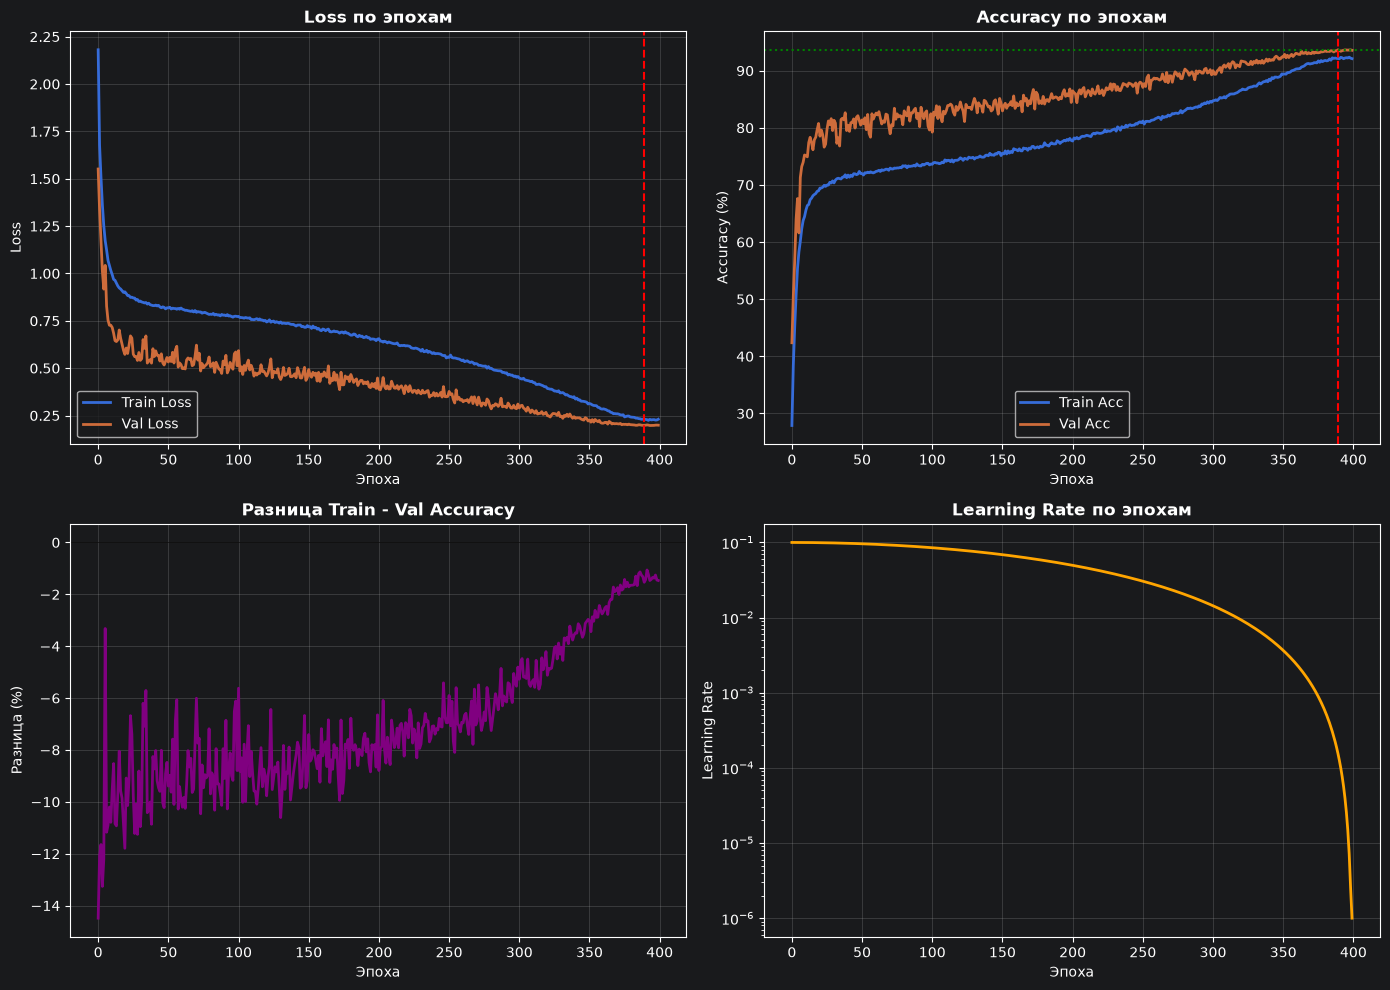

In [137]:
print("=" * 50)
print("ГРАФИКИ ОБУЧЕНИЯ")
print("=" * 50)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# График Loss
axes[0, 0].plot(train_losses, label='Train Loss', linewidth=2)
axes[0, 0].plot(val_losses, label='Val Loss', linewidth=2)
axes[0, 0].set_title('Loss по эпохам', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Эпоха')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].axvline(x=best_epoch - 1, color='r', linestyle='--', label=f'Best epoch ({best_epoch})')

# График Accuracy
axes[0, 1].plot(train_accs, label='Train Acc', linewidth=2)
axes[0, 1].plot(val_accs, label='Val Acc', linewidth=2)
axes[0, 1].set_title('Accuracy по эпохам', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Эпоха')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].axvline(x=best_epoch - 1, color='r', linestyle='--', label=f'Best epoch ({best_epoch})')
axes[0, 1].axhline(y=best_val_acc, color='g', linestyle=':', label=f'Best Val Acc: {best_val_acc:.2f}%')

# Разница между Train и Val (для выявления переобучения)
gap = [t - v for t, v in zip(train_accs, val_accs)]
axes[1, 0].plot(gap, color='purple', linewidth=2)
axes[1, 0].set_title('Разница Train - Val Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Эпоха')
axes[1, 0].set_ylabel('Разница (%)')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].axhline(y=0, color='k', linestyle='-', linewidth=0.5)

# Learning Rate по эпохам
axes[1, 1].plot(learning_rates, color='orange', linewidth=2)
axes[1, 1].set_title('Learning Rate по эпохам', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Эпоха')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_yscale('log')  # Логарифмическая шкала для наглядности
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [138]:
print("=" * 50)
print("ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ (из переменной)")
print("=" * 50)

# Если вдруг обучение прервалось и best_model не создалась, берем последнюю
model_to_test = best_model if best_model is not None else model

model_to_test.eval()
print(f" Используем модель с лучшей эпохи ({best_epoch})")
print(f" Val Accuracy была: {best_val_acc:.2f}%")
print()

test_correct, test_total, test_loss = 0, 0, 0.0
all_preds, all_labels = [], []

with torch.no_grad():
    test_pbar = tqdm(test_loader, desc="Testing")
    for images, labels in test_pbar:
        images, labels = images.to(device), labels.to(device)

        outputs = model_to_test(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        test_correct += (predicted == labels).sum().item()
        test_total += labels.size(0)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = test_correct / test_total * 100
test_loss = test_loss / test_total

print(f"{'=' * 50}")
print(f"РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ")
print(f"{'=' * 50}")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ (из переменной)
 Используем модель с лучшей эпохи (390)
 Val Accuracy была: 93.66%



Testing: 100%|██████████| 79/79 [00:03<00:00, 22.22it/s]

РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ
Test Loss:     0.2101
Test Accuracy: 93.47%



ДЕТАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ
              precision    recall  f1-score   support

    airplane      0.945     0.933     0.939      1000
  automobile      0.965     0.976     0.971      1000
        bird      0.928     0.898     0.913      1000
         cat      0.896     0.824     0.858      1000
        deer      0.931     0.955     0.943      1000
         dog      0.861     0.919     0.889      1000
        frog      0.941     0.966     0.953      1000
       horse      0.970     0.956     0.963      1000
        ship      0.955     0.965     0.960      1000
       truck      0.957     0.955     0.956      1000

    accuracy                          0.935     10000
   macro avg      0.935     0.935     0.934     10000
weighted avg      0.935     0.935     0.934     10000



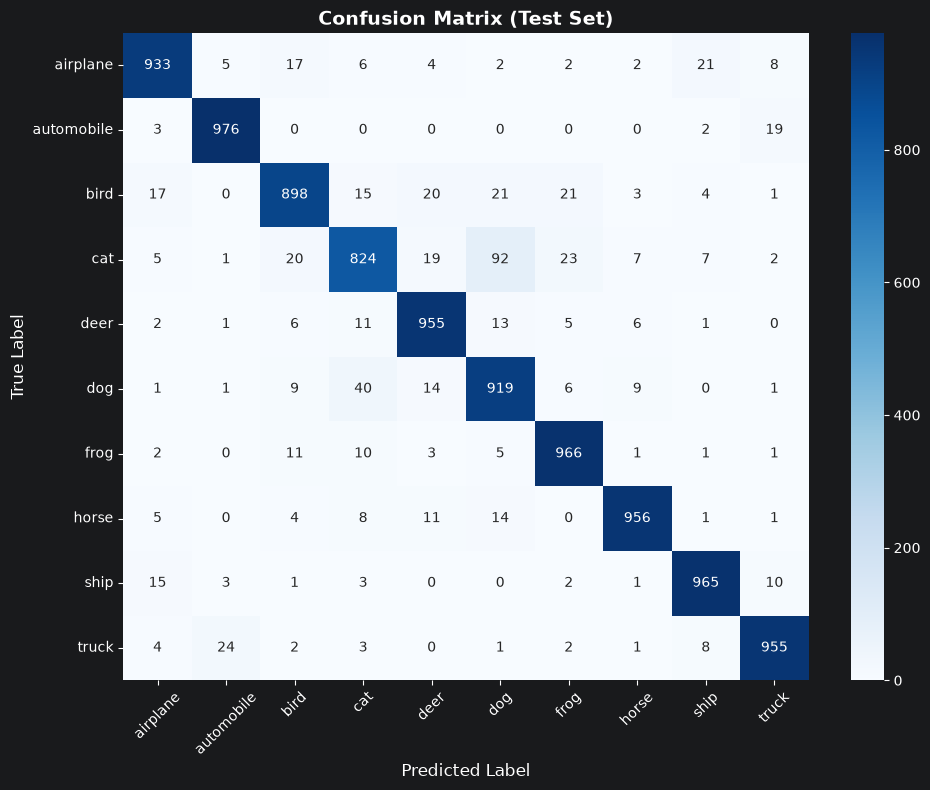

In [139]:
print("\n" + "=" * 50)
print("ДЕТАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ")
print("=" * 50)

# Classification Report
report = classification_report(
    all_labels,
    all_preds,
    target_names=CLASSES,
    digits=3
)
print(report)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [140]:
total, trainable = count_params(model)
print(f"Всего:      {total:,}")
print(f"Обучаемых:  {trainable:,} ({trainable/1e6:.2f} млн)")

Всего:      3,251,018
Обучаемых:  3,251,018 (3.25 млн)


In [141]:
print("ВТОРАЯ МОДЕЛЬ НА ОСНОВЕ WideResNet-28-10")

ВТОРАЯ МОДЕЛЬ НА ОСНОВЕ WideResNet-28-10


In [142]:
class BasicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride, drop=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_c)
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.drop = drop
        self.shortcut = None
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Conv2d(in_c, out_c, 1, stride, bias=False)

    def forward(self, x):
        o = torch.relu(self.bn1(x))
        sc = self.shortcut(o) if self.shortcut is not None else x
        o = self.conv1(o)
        o = torch.relu(self.bn2(o))
        if self.drop > 0:
            o = nn.functional.dropout(o, p=self.drop, training=self.training)
        o = self.conv2(o)
        return o + sc


class WideResNet(nn.Module):
    def __init__(self, depth=28, widen=10, num_classes=10, drop=0.0):
        super().__init__()
        n = (depth - 4) // 6
        w = [16, 16 * widen, 32 * widen, 64 * widen]
        self.conv1 = nn.Conv2d(3, w[0], 3, 1, 1, bias=False)

        def group(in_c, out_c, stride):
            layers = [BasicBlock(in_c, out_c, stride, drop)]
            layers += [BasicBlock(out_c, out_c, 1, drop) for _ in range(n - 1)]
            return nn.Sequential(*layers)

        self.g1 = group(w[0], w[1], 1)
        self.g2 = group(w[1], w[2], 2)
        self.g3 = group(w[2], w[3], 2)
        self.bn = nn.BatchNorm2d(w[3])
        self.fc = nn.Linear(w[3], num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.g3(self.g2(self.g1(x)))
        x = torch.relu(self.bn(x))
        x = nn.functional.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

model = WideResNet(28, 10).to(device)

In [143]:
# Оборачиваем наш "сырой" train_full
train_for_stats = DatasetWithToTensor(train_full)

# Считаем mean и std (используем num_workers=0 для стабильности в Jupyter/Windows)
mean, std = compute_mean_std(train_for_stats, num_workers=0)

Подсчет mean и std...


In [144]:
# Вычисляем среднее и стандартное отклонение по RGB, так как нужно превести изображеняи к числам, чтобы модель плавнее обучала необходимо произвести нормализацию, чтобы превести к числам близкие к 0
print(f"Mean: {[round(m, 4) for m in mean]}")
print(f"Std:  {[round(s, 4) for s in std]}")

Mean: [0.4914, 0.4822, 0.4465]
Std:  [0.247, 0.2435, 0.2616]


In [145]:
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(),
    transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),
])

In [146]:
# Проводим нормализацию для тестовой и валидационной выборки
val_test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

print("Train transform: аугментации + нормализация")
print("Val/Test transform: только нормализация")

Train transform: аугментации + нормализация
Val/Test transform: только нормализация


In [147]:
print("СОЗДАНИЕ ФИНАЛЬНЫХ ДАТАСЕТОВ")

СОЗДАНИЕ ФИНАЛЬНЫХ ДАТАСЕТОВ


In [148]:
train_data = DatasetWithTransform(train_full, idx_train, train_tf)
val_data = DatasetWithTransform(train_full, idx_val, val_test_tf)
test_data = DatasetWithTransform(test_full, list(range(len(test_full))), val_test_tf)

print(f"Train: {len(train_data)} изображений")
print(f"Val:   {len(val_data)} изображений")
print(f"Test:  {len(test_data)} изображений")

Train: 45000 изображений
Val:   5000 изображений
Test:  10000 изображений


In [149]:
print("ВИЗУАЛИЗАЦИЯ АУГМЕНТАЦИЙ (8 примеров)")

ВИЗУАЛИЗАЦИЯ АУГМЕНТАЦИЙ (8 примеров)


ПОКАЗ АУГМЕНТАЦИЙ НА ТЕСТОВЫХ ИЗОБРАЖЕНИЯХ
Для каждого класса: 3 примера × (1 оригинал + 4 аугментации)


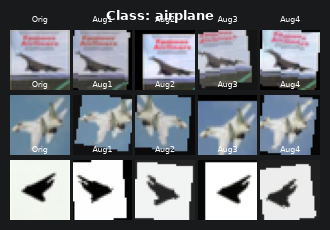

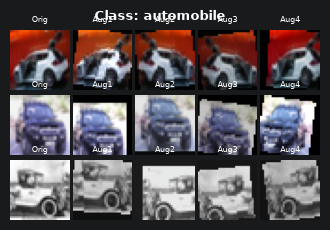

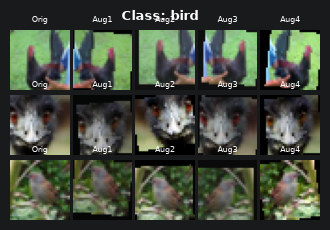

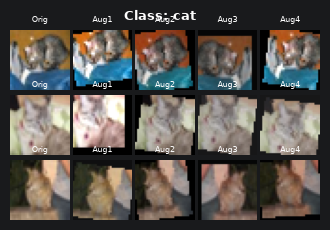

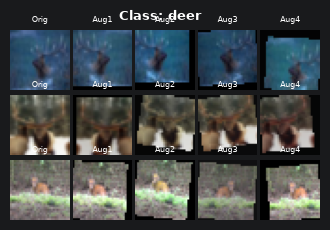

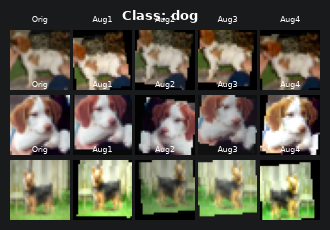

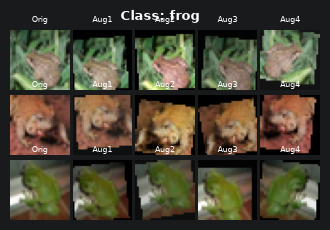

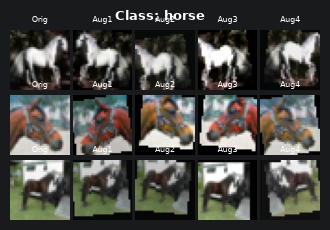

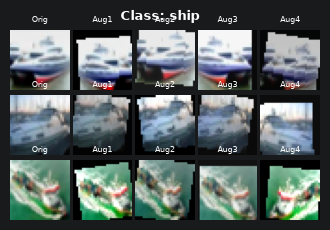

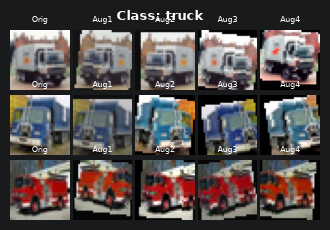

In [150]:
# ВЫЗОВ ФУНКЦИИ
print("ПОКАЗ АУГМЕНТАЦИЙ НА ТЕСТОВЫХ ИЗОБРАЖЕНИЯХ")
print("Для каждого класса: 3 примера × (1 оригинал + 4 аугментации)")

# Классы CIFAR-10
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

# Вызываем нашу новую функцию
show_augmented_samples(
    dataset=test_full,
    classes=CLASSES,
    samples_per_class=3,  # 3 примера на класс
    num_augs=4            # 4 аугментации на каждый пример
)

In [151]:
print("СОЗДАНИЕ DATALOADER'ОВ")

BATCH_SIZE = 128
NUM_WORKERS = 0

# Train DataLoader (с перемешиванием)
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,       # перемешиваем для обучения
    num_workers=NUM_WORKERS,
    pin_memory=True     # ускоряет перенос на GPU (если есть)
)

# Val DataLoader (без перемешивания)
val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Test DataLoader (без перемешивания)
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f" Train: {len(train_loader)} батчей × {BATCH_SIZE} = {len(train_data)} изображений")
print(f" Val:   {len(val_loader)} батчей × {BATCH_SIZE} = {len(val_data)} изображений")
print(f" Test:  {len(test_loader)} батчей × {BATCH_SIZE} = {len(test_data)} изображений")

СОЗДАНИЕ DATALOADER'ОВ
 Train: 352 батчей × 128 = 45000 изображений
 Val:   40 батчей × 128 = 5000 изображений
 Test:  79 батчей × 128 = 10000 изображений


In [152]:
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA compiled:   {torch.version.cuda}")
print(f"CUDA available:  {torch.cuda.is_available()}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"  Используемое устройство: {str(device).upper()}")

# Посчитаем количество обучаемых параметров
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Всего обучаемых параметров: {total_params:,}")
print(f"( {total_params / 1_000_000:.2f} млн)")
# Добавим оптимизацию, функцию потерь и метрики для оценки модели

# Устройство
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Устройство: {device}")

# Функция потерь
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

PyTorch version: 2.6.0+cu124
CUDA compiled:   12.4
CUDA available:  True
  Используемое устройство: CUDA
Всего обучаемых параметров: 36,479,194
( 36.48 млн)
 Устройство: cuda


In [153]:
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9,
                      weight_decay=5e-4, nesterov=True)
scheduler = optim.lr_scheduler.SequentialLR(
    optimizer,
    [optim.lr_scheduler.LinearLR(optimizer, 0.01, 1.0, total_iters=5),
     optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=195, eta_min=1e-5)],
    milestones=[5])

In [154]:
# CutMix: вырезает случайный прямоугольник из одной картинки и вставляет в другую.
# Возвращает: mixed_x, ya, yb, lam

def cutmix_data(x, y, alpha=1.0):

    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)

    # Размер вырезаемой области
    cut_rat = np.sqrt(1.0 - lam)
    cut_w = int(x.size(3) * cut_rat)
    cut_h = int(x.size(2) * cut_rat)

    # Случайный центр
    cx = np.random.randint(x.size(3))
    cy = np.random.randint(x.size(2))

    # Координаты прямоугольника (с ограничением краёв)
    bbx1 = np.clip(cx - cut_w // 2, 0, x.size(3))
    bby1 = np.clip(cy - cut_h // 2, 0, x.size(2))
    bbx2 = np.clip(cx + cut_w // 2, 0, x.size(3))
    bby2 = np.clip(cy + cut_h // 2, 0, x.size(2))

    # Заменяем прямоугольник на кусок из другой картинки
    x[:, :, bby1:bby2, bbx1:bbx2] = x[index, :, bby1:bby2, bbx1:bbx2]

    # Пересчитываем lam по реальной площади (точнее, чем из beta)
    lam = 1 - ((bbx2 - bbx1) * (bby2 - bby1) / (x.size(3) * x.size(2)))

    return x, y, y[index], lam

In [155]:
NUM_EPOCHS = 400

# Считает forward/backward в float16, веса хранит в float32. Ускоряет обучение и экономит память

# Mixed Precision Scaler (только для CUDA)
scaler = torch.amp.GradScaler('cuda')
print(" GradScaler инициализирован для AMP")

 GradScaler инициализирован для AMP


In [156]:
print("=" * 50)
print("ОБУЧЕНИЕ С CUTMIX + AMP (Mixed Precision)")
print("=" * 50)

# Параметры обучения
best_val_acc = 0.0
best_model = None
best_epoch = 0

# Early Stopping
patience = 80
min_delta = 0.05
counter = 0
early_stop = False

train_losses, train_accs = [], []
val_losses, val_accs = [], []
learning_rates = []

print(f"Начинаем обучение на {NUM_EPOCHS} эпох...")
print(f"Устройство: {device}")
print(f"Размер батча: {BATCH_SIZE}")
print(f"CutMix: p=0.5, alpha=1.0")
print(f"AMP: float16 (GradScaler)")
print(f"Early Stopping: patience={patience}, min_delta={min_delta}")
print("-" * 50)

start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    # ТРЕНИРОВКА
    model.train()

    epoch_train_loss = 0.0
    epoch_train_correct = 0
    epoch_train_total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Train]", leave=False)

    for images, labels in train_pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # CutMix
        use_cutmix = np.random.rand() < 0.5
        if use_cutmix:
            images, ya, yb, lam = cutmix_data(images, labels, alpha=1.0)

        # AMP
        with torch.amp.autocast('cuda', dtype=torch.float16):
            outputs = model(images)

            if use_cutmix:
                loss = lam * criterion(outputs, ya) + (1 - lam) * criterion(outputs, yb)
            else:
                loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Статистика
        epoch_train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        if use_cutmix:
            # Мягкая точность
            correct = (lam * (predicted == ya).float() + (1 - lam) * (predicted == yb).float()).sum().item()
            epoch_train_correct += correct
        else:
            epoch_train_correct += (predicted == labels).sum().item()

        epoch_train_total += labels.size(0)

        train_pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{(predicted == labels).float().mean().item() * 100:.1f}%',
            'cmix': 'Y' if use_cutmix else 'N'
        })

    avg_train_loss = epoch_train_loss / epoch_train_total
    avg_train_acc = epoch_train_correct / epoch_train_total * 100

    # ВАЛИДАЦИЯ
    model.eval()

    epoch_val_loss = 0.0
    epoch_val_correct = 0
    epoch_val_total = 0

    with torch.no_grad():
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Val]  ", leave=False)

        for images, labels in val_pbar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            epoch_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            epoch_val_correct += (predicted == labels).sum().item()
            epoch_val_total += labels.size(0)

            val_pbar.set_postfix({
                'loss': f'{loss.item():.4f}',
                'acc': f'{(predicted == labels).float().mean().item() * 100:.1f}%'
            })

    avg_val_loss = epoch_val_loss / epoch_val_total
    avg_val_acc = epoch_val_correct / epoch_val_total * 100

    # SCHEDULER
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    # ИСТОРИЯ
    train_losses.append(avg_train_loss)
    train_accs.append(avg_train_acc)
    val_losses.append(avg_val_loss)
    val_accs.append(avg_val_acc)
    learning_rates.append(current_lr)

    # ЛУЧШАЯ МОДЕЛЬ + EARLY STOPPING
    if avg_val_acc > best_val_acc + min_delta:
        best_val_acc = avg_val_acc
        best_epoch = epoch
        best_model = copy.deepcopy(model)
        counter = 0

        # Сохраняем на диск
        torch.save({
            'epoch': epoch,
            'model_state_dict': best_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_acc': best_val_acc,
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
        }, 'best_wrn.pth')

        print(f"  Новая лучшая модель! Val Acc: {avg_val_acc:.2f}% (сохранена)")
    else:
        counter += 1
        print(f"  Val Acc: {avg_val_acc:.2f}% (лучшая: {best_val_acc:.2f}% на эпохе {best_epoch}) | "
              f"без улучшения: {counter}/{patience}")

        if counter >= patience:
            print(f"\nРанняя остановка на эпохе {epoch}! "
                  f"Точность не улучшалась {patience} эпох.")
            early_stop = True

    # Вывод статистики эпохи (всегда на одном уровне)
    print(f"  Epoch {epoch}/{NUM_EPOCHS} | "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.2f}% | "
          f"LR: {current_lr:.6f}")
    print("-" * 50)

    if early_stop:
        break

# ИТОГ
end_time = time.time()
total_time = end_time - start_time

print(f"\n{'=' * 50}")
print(f"ОБУЧЕНИЕ ЗАВЕРШЕНО!")
print(f"{'=' * 50}")
print(f"Время обучения: {total_time / 60:.1f} минут")
print(f"Лучшая точность на валидации: {best_val_acc:.2f}% (эпоха {best_epoch})")

ОБУЧЕНИЕ С CUTMIX + AMP (Mixed Precision)
Начинаем обучение на 400 эпох...
Устройство: cuda
Размер батча: 128
CutMix: p=0.5, alpha=1.0
AMP: float16 (GradScaler)
Early Stopping: patience=80, min_delta=0.05
--------------------------------------------------


  Новая лучшая модель! Val Acc: 43.44% (сохранена)
  Epoch 1/400 | Train Loss: 2.1257 | Train Acc: 23.38% | Val Loss: 1.7143 | Val Acc: 43.44% | LR: 0.020800
--------------------------------------------------


  Новая лучшая модель! Val Acc: 57.88% (сохранена)
  Epoch 2/400 | Train Loss: 1.9065 | Train Acc: 35.87% | Val Loss: 1.4261 | Val Acc: 57.88% | LR: 0.040600
--------------------------------------------------


  Новая лучшая модель! Val Acc: 67.58% (сохранена)
  Epoch 3/400 | Train Loss: 1.7191 | Train Acc: 46.46% | Val Loss: 1.2323 | Val Acc: 67.58% | LR: 0.060400
--------------------------------------------------


  Новая лучшая модель! Val Acc: 76.02% (сохранена)
  Epoch 4/400 | Train Loss: 1.5889 | Train Acc: 52.99% | Val Loss: 1.0721 | Val Acc: 76.02% | LR: 0.080200
--------------------------------------------------


C:\Users\Pedant\Desktop\cifar10-classification\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:243: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


... (263 outputs left out)

  Val Acc: 93.50% (лучшая: 97.74% на эпохе 191) | без улучшения: 77/80
  Epoch 268/400 | Train Loss: 1.0210 | Train Acc: 77.87% | Val Loss: 0.6581 | Val Acc: 93.50% | LR: 0.027129
--------------------------------------------------


  Val Acc: 93.32% (лучшая: 97.74% на эпохе 191) | без улучшения: 78/80
  Epoch 269/400 | Train Loss: 1.0348 | Train Acc: 77.10% | Val Loss: 0.6785 | Val Acc: 93.32% | LR: 0.027848
--------------------------------------------------


  Val Acc: 92.32% (лучшая: 97.74% на эпохе 191) | без улучшения: 79/80
  Epoch 270/400 | Train Loss: 1.0202 | Train Acc: 78.09% | Val Loss: 0.6814 | Val Acc: 92.32% | LR: 0.028573
--------------------------------------------------


  Val Acc: 93.00% (лучшая: 97.74% на эпохе 191) | без улучшения: 80/80

Ранняя остановка на эпохе 271! Точность не улучшалась 80 эпох.
  Epoch 271/400 | Train Loss: 1.0045 | Train Acc: 78.31% | Val Loss: 0.6625 | Val Acc: 93.00% | LR: 0.029303
--------------------------------------------------

ОБУЧЕНИЕ ЗАВЕРШЕНО!
Время обучения: 597.4 минут
Лучшая точность на валидации: 97.74% (эпоха 191)


ГРАФИКИ ОБУЧЕНИЯ


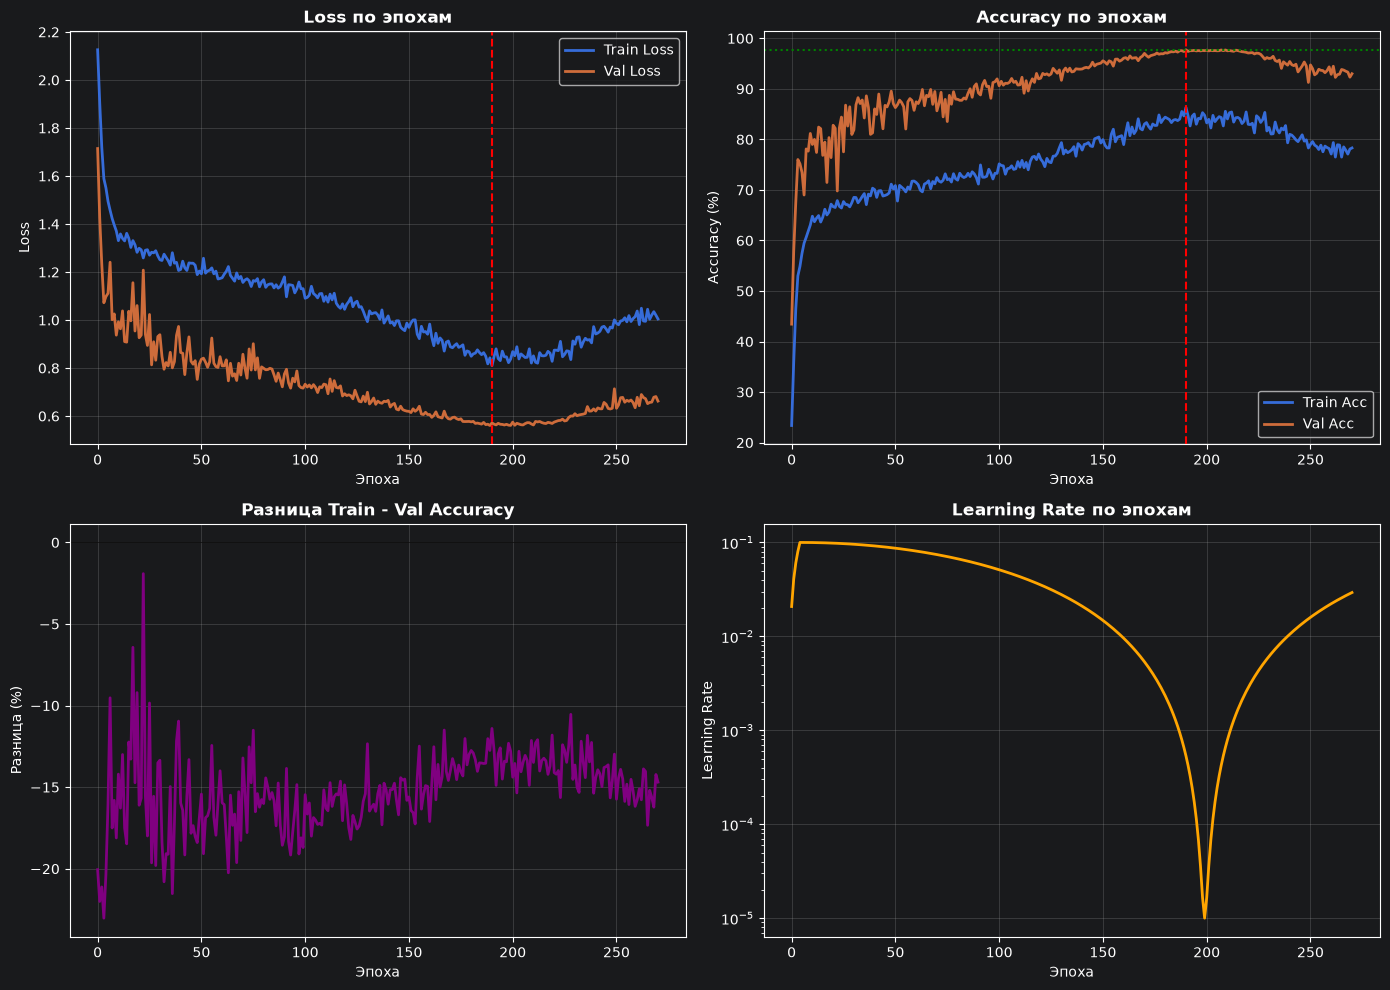

In [157]:
print("=" * 50)
print("ГРАФИКИ ОБУЧЕНИЯ")
print("=" * 50)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# График Loss
axes[0, 0].plot(train_losses, label='Train Loss', linewidth=2)
axes[0, 0].plot(val_losses, label='Val Loss', linewidth=2)
axes[0, 0].set_title('Loss по эпохам', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Эпоха')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].axvline(x=best_epoch - 1, color='r', linestyle='--', label=f'Best epoch ({best_epoch})')

# График Accuracy
axes[0, 1].plot(train_accs, label='Train Acc', linewidth=2)
axes[0, 1].plot(val_accs, label='Val Acc', linewidth=2)
axes[0, 1].set_title('Accuracy по эпохам', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Эпоха')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].axvline(x=best_epoch - 1, color='r', linestyle='--', label=f'Best epoch ({best_epoch})')
axes[0, 1].axhline(y=best_val_acc, color='g', linestyle=':', label=f'Best Val Acc: {best_val_acc:.2f}%')

# Разница между Train и Val (для выявления переобучения)
gap = [t - v for t, v in zip(train_accs, val_accs)]
axes[1, 0].plot(gap, color='purple', linewidth=2)
axes[1, 0].set_title('Разница Train - Val Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Эпоха')
axes[1, 0].set_ylabel('Разница (%)')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].axhline(y=0, color='k', linestyle='-', linewidth=0.5)

# Learning Rate по эпохам
axes[1, 1].plot(learning_rates, color='orange', linewidth=2)
axes[1, 1].set_title('Learning Rate по эпохам', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Эпоха')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_yscale('log')  # Логарифмическая шкала для наглядности
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [158]:
print("=" * 50)
print("ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ (из переменной)")
print("=" * 50)

# Если вдруг обучение прервалось и best_model не создалась, берем последнюю
model_to_test = best_model if best_model is not None else model

model_to_test.eval()
print(f" Используем модель с лучшей эпохи ({best_epoch})")
print(f" Val Accuracy была: {best_val_acc:.2f}%")
print()

test_correct, test_total, test_loss = 0, 0, 0.0
all_preds, all_labels = [], []

with torch.no_grad():
    test_pbar = tqdm(test_loader, desc="Testing")
    for images, labels in test_pbar:
        images, labels = images.to(device), labels.to(device)

        outputs = model_to_test(images)  # <-- Используем best_model
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        test_correct += (predicted == labels).sum().item()
        test_total += labels.size(0)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = test_correct / test_total * 100
test_loss = test_loss / test_total

print(f"{'=' * 50}")
print(f"РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ")
print(f"{'=' * 50}")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ (из переменной)
 Используем модель с лучшей эпохи (191)
 Val Accuracy была: 97.74%



Testing: 100%|██████████| 79/79 [00:25<00:00,  3.05it/s]

РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ
Test Loss:     0.5834
Test Accuracy: 97.15%



ДЕТАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ
              precision    recall  f1-score   support

    airplane      0.989     0.973     0.981      1000
  automobile      0.980     0.985     0.983      1000
        bird      0.967     0.966     0.966      1000
         cat      0.943     0.917     0.930      1000
        deer      0.968     0.977     0.973      1000
         dog      0.931     0.953     0.942      1000
        frog      0.986     0.989     0.988      1000
       horse      0.989     0.988     0.988      1000
        ship      0.981     0.989     0.985      1000
       truck      0.981     0.978     0.979      1000

    accuracy                          0.972     10000
   macro avg      0.972     0.972     0.971     10000
weighted avg      0.972     0.972     0.971     10000



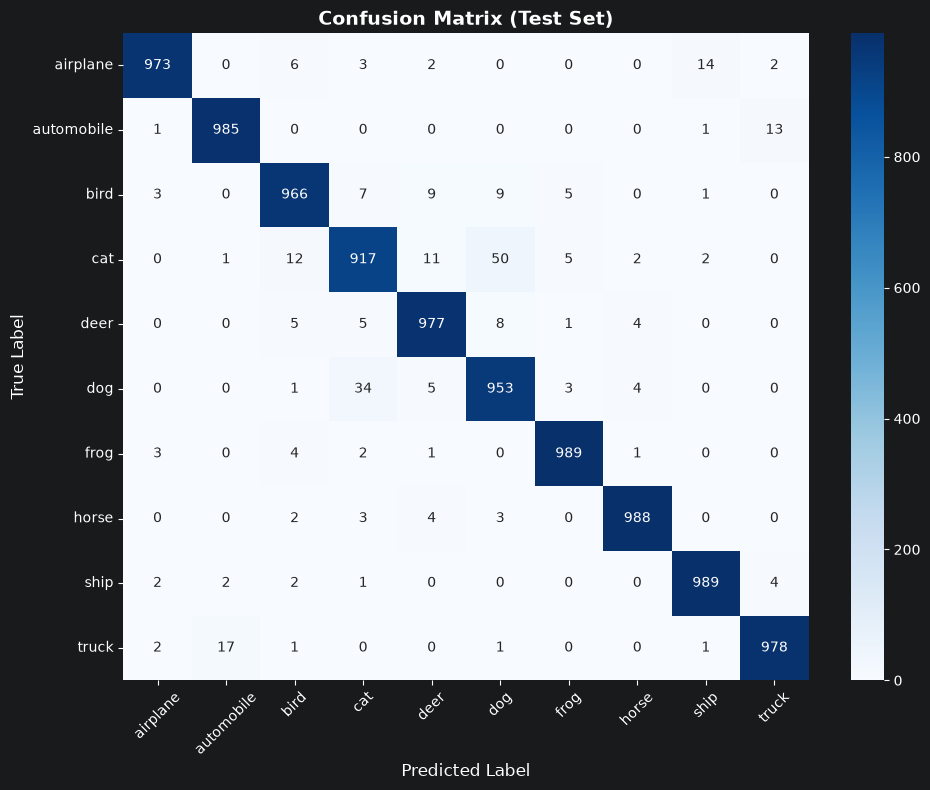

In [159]:
print("\n" + "=" * 50)
print("ДЕТАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ")
print("=" * 50)

# Classification Report
report = classification_report(
    all_labels,
    all_preds,
    target_names=CLASSES,
    digits=3
)
print(report)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [160]:
total, trainable = count_params(model)
print(f"Всего:      {total:,}")
print(f"Обучаемых:  {trainable:,} ({trainable/1e6:.2f} млн)")

Всего:      36,479,194
Обучаемых:  36,479,194 (36.48 млн)


In [161]:
print("ТРЕТЬЯ МОДЕЛЬ НА ОСНОВЕ WideResNet-28-10")

ТРЕТЬЯ МОДЕЛЬ НА ОСНОВЕ WideResNet-28-10


In [162]:
# WideResNet-28-4

class BasicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride, drop=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_c)
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.drop = drop
        self.shortcut = None
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Conv2d(in_c, out_c, 1, stride, bias=False)

    def forward(self, x):
        o = torch.relu(self.bn1(x))
        sc = self.shortcut(o) if self.shortcut is not None else x
        o = self.conv1(o)
        o = torch.relu(self.bn2(o))
        if self.drop > 0:
            o = nn.functional.dropout(o, p=self.drop, training=self.training)
        o = self.conv2(o)
        return o + sc


class WideResNet(nn.Module):
    def __init__(self, depth=28, widen=4, num_classes=10, drop=0.3):
        super().__init__()
        n = (depth - 4) // 6
        w = [16, 16 * widen, 32 * widen, 64 * widen]   # 16, 64, 128, 256

        self.conv1 = nn.Conv2d(3, w[0], 3, 1, 1, bias=False)

        def group(in_c, out_c, stride):
            layers = [BasicBlock(in_c, out_c, stride, drop)]
            layers += [BasicBlock(out_c, out_c, 1, drop) for _ in range(n - 1)]
            return nn.Sequential(*layers)

        self.g1 = group(w[0], w[1], 1)
        self.g2 = group(w[1], w[2], 2)
        self.g3 = group(w[2], w[3], 2)
        self.bn = nn.BatchNorm2d(w[3])
        self.fc = nn.Linear(w[3], num_classes)

        # Инициализация
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.conv1(x)
        x = self.g1(x)
        x = self.g2(x)
        x = self.g3(x)
        x = torch.relu(self.bn(x))
        x = nn.functional.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

In [163]:
model = WideResNet(depth=28, widen=4, num_classes=10, drop=0.3).to(device)

In [164]:
# Оптимизатор, scheduler, criterion

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True
)

# Warm-up 5 эпох + Cosine
scheduler = optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=5),
        optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=195, eta_min=1e-5)
    ],
    milestones=[5]
)

In [165]:
# Обучение

NUM_EPOCHS = 200
BATCH_SIZE = 128

best_val_acc = 0.0
best_model = None
best_epoch = 0

# Early Stopping
patience = 80
min_delta = 0.05
counter = 0
early_stop = False

train_losses, train_accs = [], []
val_losses, val_accs = [], []
learning_rates = []

print("=" * 60)
print("ОБУЧЕНИЕ WideResNet-28-4 + CutMix + AMP")
print("=" * 60)
print(f"Эпох: {NUM_EPOCHS} | Batch: {BATCH_SIZE}")
print(f"Early Stopping: patience={patience}")
print("-" * 60)

ОБУЧЕНИЕ WideResNet-28-4 + CutMix + AMP
Эпох: 200 | Batch: 128
Early Stopping: patience=80
------------------------------------------------------------


In [166]:
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    epoch_train_loss = 0.0
    epoch_train_correct = 0
    epoch_train_total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Train]", leave=False)

    for images, labels in train_pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # CutMix
        use_cutmix = np.random.rand() < 0.5
        if use_cutmix:
            images, ya, yb, lam = cutmix_data(images, labels, alpha=1.0)

        # AMP forward
        with torch.amp.autocast('cuda', dtype=torch.float16):
            outputs = model(images)
            if use_cutmix:
                loss = lam * criterion(outputs, ya) + (1 - lam) * criterion(outputs, yb)
            else:
                loss = criterion(outputs, labels)

        # AMP backward
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accuracy
        epoch_train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        if use_cutmix:
            correct = (lam * (predicted == ya).float() + (1 - lam) * (predicted == yb).float()).sum().item()
            epoch_train_correct += correct
        else:
            epoch_train_correct += (predicted == labels).sum().item()

        epoch_train_total += labels.size(0)

        train_pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{(predicted == labels).float().mean().item()*100:.1f}%',
            'cmix': 'Y' if use_cutmix else 'N'
        })

    avg_train_loss = epoch_train_loss / epoch_train_total
    avg_train_acc = epoch_train_correct / epoch_train_total * 100

    # VALIDATION
    model.eval()
    epoch_val_loss = 0.0
    epoch_val_correct = 0
    epoch_val_total = 0

    with torch.no_grad():
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Val]  ", leave=False)
        for images, labels in val_pbar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            epoch_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            epoch_val_correct += (predicted == labels).sum().item()
            epoch_val_total += labels.size(0)

            val_pbar.set_postfix({
                'loss': f'{loss.item():.4f}',
                'acc': f'{(predicted == labels).float().mean().item()*100:.1f}%'
            })

    avg_val_loss = epoch_val_loss / epoch_val_total
    avg_val_acc = epoch_val_correct / epoch_val_total * 100

    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    train_losses.append(avg_train_loss)
    train_accs.append(avg_train_acc)
    val_losses.append(avg_val_loss)
    val_accs.append(avg_val_acc)
    learning_rates.append(current_lr)

    # Best model + Early Stopping
    if avg_val_acc > best_val_acc + min_delta:
        best_val_acc = avg_val_acc
        best_epoch = epoch
        best_model = copy.deepcopy(model)
        counter = 0

        # Сохраняем на диск
        torch.save({
            'epoch': epoch,
            'model_state_dict': best_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_acc': best_val_acc,
        }, 'best_wrn28_4.pth')

        print(f"  Новая лучшая модель! Val Acc: {avg_val_acc:.2f}% → сохранена в best_wrn28_4.pth")
    else:
        counter += 1
        print(f"  Val Acc: {avg_val_acc:.2f}% | лучшая: {best_val_acc:.2f}% (эп. {best_epoch}) | "
              f"без улучшения: {counter}/{patience}")

        if counter >= patience:
            print(f"\nРанняя остановка на эпохе {epoch}!")
            early_stop = True

    print(f"  Epoch {epoch:03d} | "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {avg_train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.2f}% | "
          f"LR: {current_lr:.6f}")
    print("-" * 60)

    if early_stop:
        break

  Новая лучшая модель! Val Acc: 8.98% → сохранена в best_wrn28_4.pth
  Epoch 001 | Train Loss: 2.2962 | Train Acc: 12.19% | Val Loss: 2.2978 | Val Acc: 8.98% | LR: 0.020800
------------------------------------------------------------


  Новая лучшая модель! Val Acc: 34.36% → сохранена в best_wrn28_4.pth
  Epoch 002 | Train Loss: 2.1373 | Train Acc: 21.37% | Val Loss: 1.8864 | Val Acc: 34.36% | LR: 0.040600
------------------------------------------------------------


  Новая лучшая модель! Val Acc: 52.78% → сохранена в best_wrn28_4.pth
  Epoch 003 | Train Loss: 1.9724 | Train Acc: 31.91% | Val Loss: 1.5313 | Val Acc: 52.78% | LR: 0.060400
------------------------------------------------------------


  Новая лучшая модель! Val Acc: 63.32% → сохранена в best_wrn28_4.pth
  Epoch 004 | Train Loss: 1.8022 | Train Acc: 41.44% | Val Loss: 1.3313 | Val Acc: 63.32% | LR: 0.080200
------------------------------------------------------------


C:\Users\Pedant\Desktop\cifar10-classification\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:243: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


  Новая лучшая модель! Val Acc: 64.44% → сохранена в best_wrn28_4.pth
  Epoch 005 | Train Loss: 1.7095 | Train Acc: 46.24% | Val Loss: 1.2796 | Val Acc: 64.44% | LR: 0.100000
------------------------------------------------------------


... (191 outputs left out)

  Val Acc: 96.52% | лучшая: 96.74% (эп. 192) | без улучшения: 5/80
  Epoch 197 | Train Loss: 0.9543 | Train Acc: 80.63% | Val Loss: 0.5887 | Val Acc: 96.52% | LR: 0.000068
------------------------------------------------------------


  Val Acc: 96.54% | лучшая: 96.74% (эп. 192) | без улучшения: 6/80
  Epoch 198 | Train Loss: 0.9764 | Train Acc: 79.66% | Val Loss: 0.5903 | Val Acc: 96.54% | LR: 0.000036
------------------------------------------------------------


  Val Acc: 96.54% | лучшая: 96.74% (эп. 192) | без улучшения: 7/80
  Epoch 199 | Train Loss: 0.9470 | Train Acc: 80.93% | Val Loss: 0.5891 | Val Acc: 96.54% | LR: 0.000016
------------------------------------------------------------


  Val Acc: 96.58% | лучшая: 96.74% (эп. 192) | без улучшения: 8/80
  Epoch 200 | Train Loss: 0.9588 | Train Acc: 80.48% | Val Loss: 0.5952 | Val Acc: 96.58% | LR: 0.000010
------------------------------------------------------------


ГРАФИКИ ОБУЧЕНИЯ


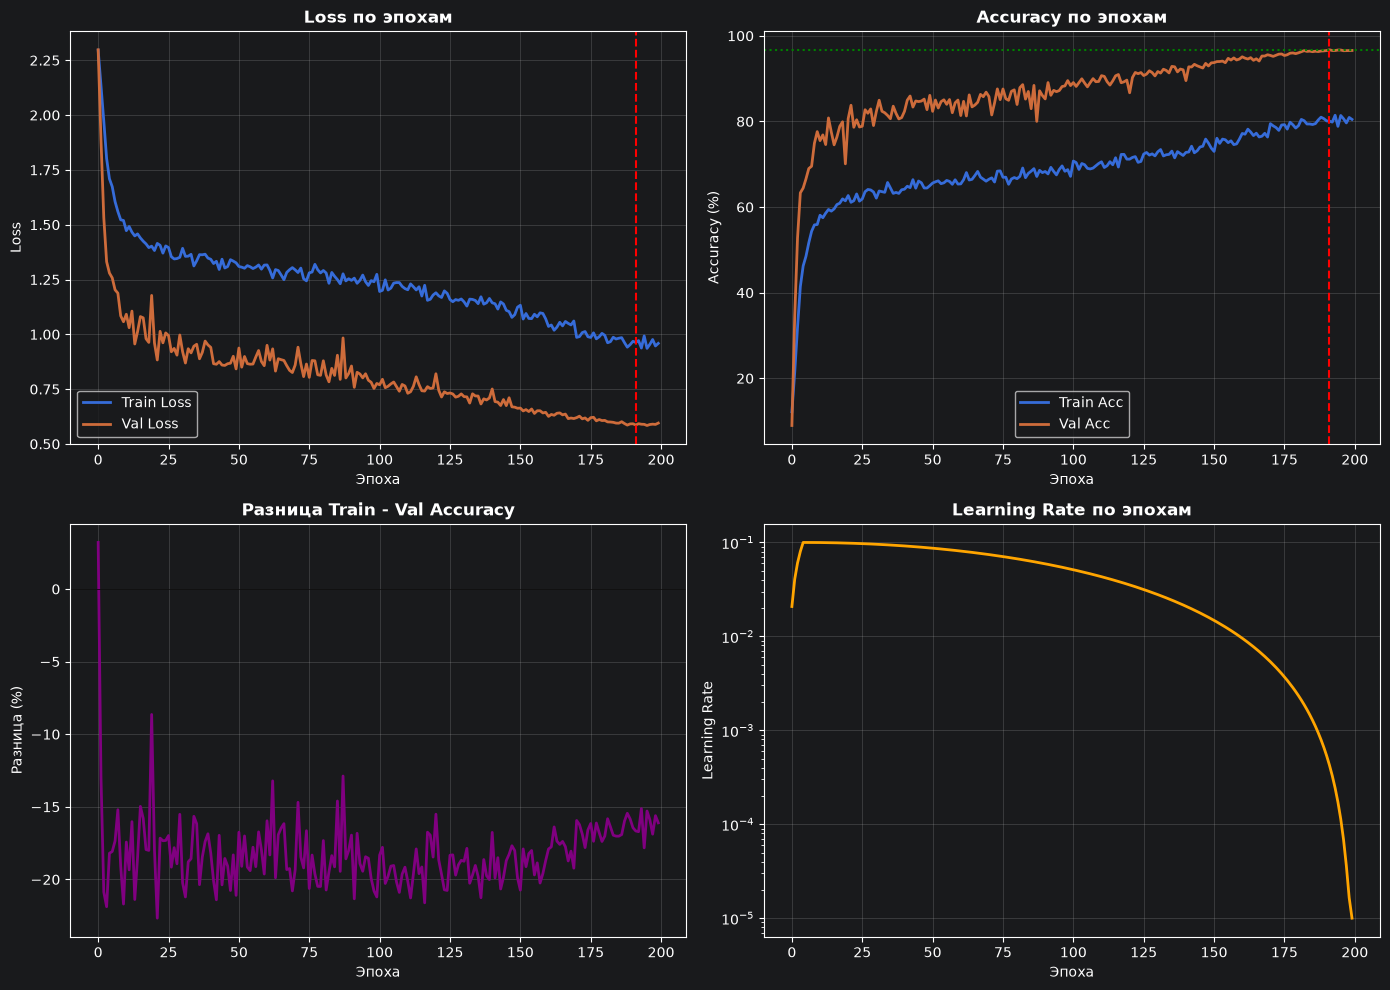

In [167]:
print("=" * 50)
print("ГРАФИКИ ОБУЧЕНИЯ")
print("=" * 50)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# График Loss
axes[0, 0].plot(train_losses, label='Train Loss', linewidth=2)
axes[0, 0].plot(val_losses, label='Val Loss', linewidth=2)
axes[0, 0].set_title('Loss по эпохам', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Эпоха')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].axvline(x=best_epoch - 1, color='r', linestyle='--', label=f'Best epoch ({best_epoch})')

# График Accuracy
axes[0, 1].plot(train_accs, label='Train Acc', linewidth=2)
axes[0, 1].plot(val_accs, label='Val Acc', linewidth=2)
axes[0, 1].set_title('Accuracy по эпохам', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Эпоха')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].axvline(x=best_epoch - 1, color='r', linestyle='--', label=f'Best epoch ({best_epoch})')
axes[0, 1].axhline(y=best_val_acc, color='g', linestyle=':', label=f'Best Val Acc: {best_val_acc:.2f}%')

# Разница между Train и Val (для выявления переобучения)
gap = [t - v for t, v in zip(train_accs, val_accs)]
axes[1, 0].plot(gap, color='purple', linewidth=2)
axes[1, 0].set_title('Разница Train - Val Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Эпоха')
axes[1, 0].set_ylabel('Разница (%)')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].axhline(y=0, color='k', linestyle='-', linewidth=0.5)

# Learning Rate по эпохам
axes[1, 1].plot(learning_rates, color='orange', linewidth=2)
axes[1, 1].set_title('Learning Rate по эпохам', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Эпоха')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_yscale('log')  # Логарифмическая шкала для наглядности
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [168]:
print("=" * 50)
print("ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ (из переменной)")
print("=" * 50)

# Если вдруг обучение прервалось и best_model не создалась, берем последнюю
model_to_test = best_model if best_model is not None else model

model_to_test.eval()
print(f" Используем модель с лучшей эпохи ({best_epoch})")
print(f" Val Accuracy была: {best_val_acc:.2f}%")
print()

test_correct, test_total, test_loss = 0, 0, 0.0
all_preds, all_labels = [], []

with torch.no_grad():
    test_pbar = tqdm(test_loader, desc="Testing")
    for images, labels in test_pbar:
        images, labels = images.to(device), labels.to(device)

        outputs = model_to_test(images)  # <-- Используем best_model
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        test_correct += (predicted == labels).sum().item()
        test_total += labels.size(0)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = test_correct / test_total * 100
test_loss = test_loss / test_total

print(f"{'=' * 50}")
print(f"РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ")
print(f"{'=' * 50}")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ (из переменной)
 Используем модель с лучшей эпохи (192)
 Val Accuracy была: 96.74%



Testing: 100%|██████████| 79/79 [00:05<00:00, 15.47it/s]

РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ
Test Loss:     0.5921
Test Accuracy: 96.38%



ДЕТАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ
              precision    recall  f1-score   support

    airplane      0.980     0.966     0.973      1000
  automobile      0.977     0.992     0.985      1000
        bird      0.951     0.959     0.955      1000
         cat      0.923     0.909     0.916      1000
        deer      0.965     0.964     0.964      1000
         dog      0.918     0.928     0.923      1000
        frog      0.982     0.974     0.978      1000
       horse      0.984     0.980     0.982      1000
        ship      0.970     0.988     0.979      1000
       truck      0.989     0.978     0.983      1000

    accuracy                          0.964     10000
   macro avg      0.964     0.964     0.964     10000
weighted avg      0.964     0.964     0.964     10000



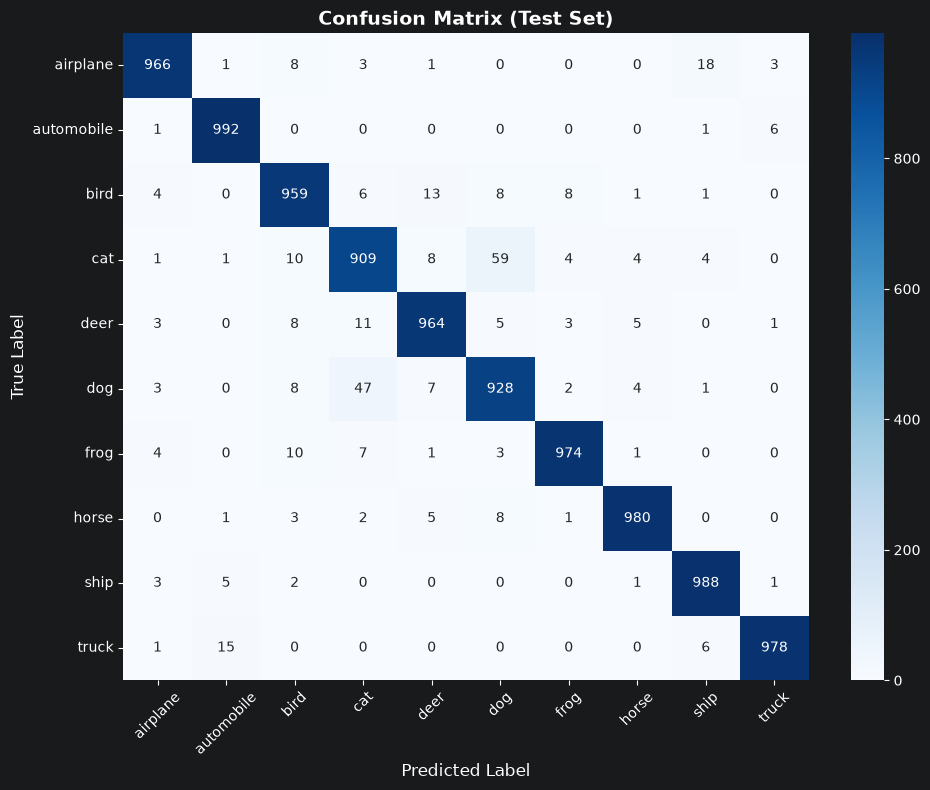

In [169]:
print("\n" + "=" * 50)
print("ДЕТАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ")
print("=" * 50)

# Classification Report
report = classification_report(
    all_labels,
    all_preds,
    target_names=CLASSES,
    digits=3
)
print(report)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [170]:
total, trainable = count_params(model)
print(f"Всего:      {total:,}")
print(f"Обучаемых:  {trainable:,} ({trainable/1e6:.2f} млн)")

Всего:      5,849,050
Обучаемых:  5,849,050 (5.85 млн)
